<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/models/3-classes/newDense_3class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install Dependencies

In [1]:
!pip install -q kagglehub

## 2. Imports & Reproducibility

In [2]:
import os, time, copy, math, random
import numpy as np
import cv2
from PIL import Image
from collections import Counter
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.backends.cudnn as cudnn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, datasets, models
from sklearn.metrics import (
    f1_score, confusion_matrix, classification_report,
    balanced_accuracy_score, cohen_kappa_score
)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
use_amp = (device == 'cuda')
cudnn.benchmark = True
print("Using device:", device, "| AMP:", use_amp)

Using device: cuda | AMP: True


## 3. Download Dataset from Kaggle

In [3]:
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)
base = path

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


## 4. Config (all the knobs in one place)

In [4]:
class_names = ["Grade 2", "Grade 3", "Grade 4"]
NUM_CLASSES = 3
IMG_SIZE    = 224
BATCH_SIZE  = 32

# Regularization
HEAD_DROPOUT     = 0.5    # dropout before the final linear layer
BLOCK_DROP_RATE  = 0.1    # dropout inside the dense layers
LABEL_SMOOTHING  = 0.1
WEIGHT_DECAY     = 0.01

# Phase 1: frozen backbone, train only the new head
P1_EPOCHS = 4
P1_LR     = 1e-3

# Phase 2: fine-tune everything
P2_EPOCHS   = 30
BACKBONE_LR = 2e-5
HEAD_LR     = 2e-4
WARMUP_EPOCHS = 1
PATIENCE    = 8           # early stopping on val Macro-F1
GRAD_CLIP   = 1.0

BEST_PATH = 'densenet201_3class_best.pt'

## 5. Pre-processing & Data Augmentation

In [5]:
# 1) Denoising & contrast enhancement (same as Xception notebook)
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))
        g = cv2.GaussianBlur(g, (3, 3), 0)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
        return Image.fromarray(g)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# 2) Validation / test pipeline (no augmentation)
eval_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# 3) Training pipeline (augmentation)
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.10), value=0),
])

## 6. Load Data (Grades 2, 3, 4 only)
Denoise + resize are deterministic, so they are computed **once** and cached in memory. Only the random augmentations run per epoch (much faster than the old pipeline).

In [6]:
class KneeGrades234(Dataset):
    def __init__(self, root, transform):
        self.transform = transform
        raw = datasets.ImageFolder(root)
        self.images, self.targets = [], []
        for p, t in tqdm(raw.samples, desc=os.path.basename(root), leave=False):
            if t >= 2:                                   # keep grades 2, 3, 4
                img = Denoise()(Image.open(p))
                img = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
                self.images.append(img)
                self.targets.append(t - 2)               # remap 2,3,4 -> 0,1,2
    def __len__(self):
        return len(self.targets)
    def __getitem__(self, i):
        return self.transform(self.images[i]), self.targets[i]

train = KneeGrades234(f"{base}/train", train_tf)
val   = KneeGrades234(f"{base}/val",   eval_tf)
test  = KneeGrades234(f"{base}/test",  eval_tf)

total_samples = len(train) + len(val) + len(test)
for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    dist = {class_names[k]: f"{v} ({v/len(ds)*100:.1f}%)" for k, v in sorted(counts.items())}
    print(f"{name:5} | Total: {len(ds):4} ({len(ds)/total_samples*100:.2f}%) | {dist}")

train:   0%|          | 0/5778 [00:00<?, ?it/s]

val:   0%|          | 0/826 [00:00<?, ?it/s]

test:   0%|          | 0/1656 [00:00<?, ?it/s]

train | Total: 2446 (69.65%) | {'Grade 2': '1516 (62.0%)', 'Grade 3': '757 (30.9%)', 'Grade 4': '173 (7.1%)'}
val   | Total:  345 (9.82%) | {'Grade 2': '212 (61.4%)', 'Grade 3': '106 (30.7%)', 'Grade 4': '27 (7.8%)'}
test  | Total:  721 (20.53%) | {'Grade 2': '447 (62.0%)', 'Grade 3': '223 (30.9%)', 'Grade 4': '51 (7.1%)'}


## 7. Class Weights & DataLoaders

In [7]:
counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (NUM_CLASSES * counts[i]) for i in range(NUM_CLASSES)]
class_weights = torch.tensor(weights, dtype=torch.float)
print("Class weights:", [round(w, 2) for w in weights])

train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val,   batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test,  batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

Class weights: [0.54, 1.08, 4.71]


## 8. Visualize Pre-processed Samples

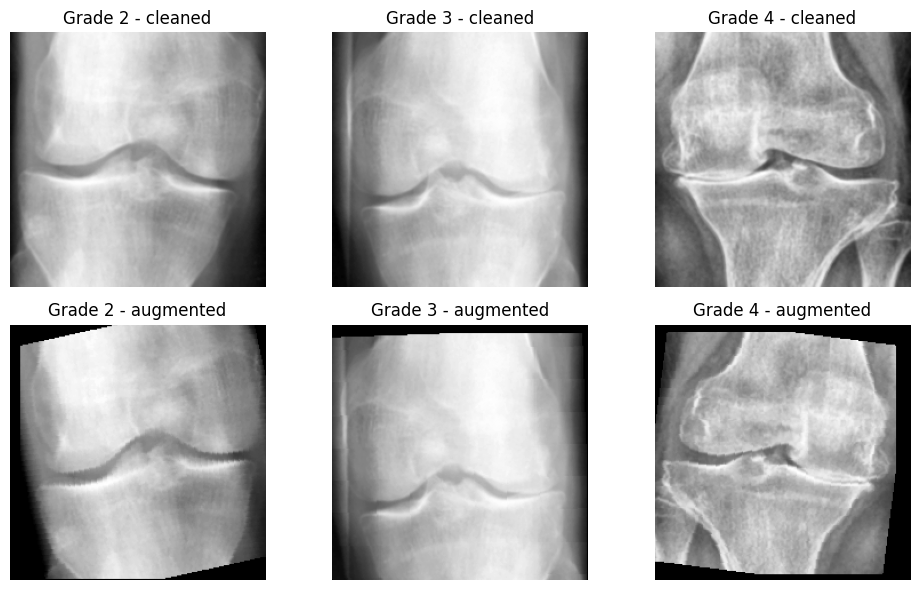

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for j in range(3):
    idx = train.targets.index(j)
    img = train.images[idx]
    aug = train_tf(img)[0]
    axes[0][j].imshow(img, cmap="gray");  axes[0][j].set_title(f"{class_names[j]} - cleaned"); axes[0][j].axis("off")
    axes[1][j].imshow(aug, cmap="gray");  axes[1][j].set_title(f"{class_names[j]} - augmented"); axes[1][j].axis("off")
plt.tight_layout(); plt.show()

## 9. Model: DenseNet-201 + new head

In [9]:
def build_model():
    m = models.densenet201(weights=models.DenseNet201_Weights.DEFAULT, drop_rate=BLOCK_DROP_RATE)
    in_f = m.classifier.in_features
    m.classifier = nn.Sequential(nn.Dropout(HEAD_DROPOUT), nn.Linear(in_f, NUM_CLASSES))
    return m.to(device)

model = build_model()
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=LABEL_SMOOTHING)
print("Params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 1))

Downloading: "https://download.pytorch.org/models/densenet201-c1103571.pth" to /root/.cache/torch/hub/checkpoints/densenet201-c1103571.pth


100%|██████████| 77.4M/77.4M [00:00<00:00, 177MB/s]


Params (M): 18.1


## 10. Training & Evaluation Helpers

In [10]:
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def train_one_epoch(model, loader, optimizer, scheduler=None, freeze_backbone=False):
    model.train()
    if freeze_backbone:
        model.features.eval()          # keep BatchNorm stats of the frozen backbone fixed
    total_loss, preds_all, labels_all = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            out = model(x)
        loss = loss_fn(out.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer); scaler.update()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * len(y)
        preds_all.extend(out.argmax(1).cpu().numpy()); labels_all.extend(y.cpu().numpy())
    n = len(labels_all)
    return {"loss": total_loss / n,
            "acc":  100 * np.mean(np.array(preds_all) == np.array(labels_all)),
            "f1":   f1_score(labels_all, preds_all, average='macro', zero_division=0)}

@torch.no_grad()
def get_logits(model, loader, tta=False):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            out = model(x)
            if tta:
                out = (out + model(torch.flip(x, dims=[3]))) / 2   # horizontal-flip TTA
        logits.append(out.float().cpu()); labels.append(y)
    return torch.cat(logits), torch.cat(labels).numpy()

def evaluate(model, loader, tta=False):
    logits, labels = get_logits(model, loader, tta)
    loss = loss_fn(logits.to(device), torch.tensor(labels).to(device)).item()
    preds = logits.argmax(1).numpy()
    return {"loss": loss,
            "acc":  100 * np.mean(preds == labels),
            "f1":   f1_score(labels, preds, average='macro', zero_division=0)}

history = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": [], "tr_f1": [], "va_f1": []}
best = {"f1": 0.0}

def fit(optimizer, epochs, name, scheduler=None, freeze_backbone=False, patience=None):
    bad = 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr = train_one_epoch(model, train_loader, optimizer, scheduler, freeze_backbone)
        va = evaluate(model, val_loader)
        for k, d in [("loss", None), ("acc", None), ("f1", None)]:
            history["tr_" + k].append(tr[k]); history["va_" + k].append(va[k])
        gap = tr["acc"] - va["acc"]
        print(f"[{name}] {ep:02d}/{epochs} | train loss {tr['loss']:.3f} acc {tr['acc']:.1f} f1 {tr['f1']:.3f} | "
              f"val loss {va['loss']:.3f} acc {va['acc']:.1f} f1 {va['f1']:.3f} | gap {gap:+.1f} | {time.time()-t0:.0f}s")
        if va["f1"] > best["f1"] + 1e-4:
            best.update(f1=va["f1"], epoch=len(history["va_f1"]), phase=name)
            torch.save(model.state_dict(), BEST_PATH)
            print(f"    --> best model saved (val Macro-F1 {va['f1']:.4f})")
            bad = 0
        else:
            bad += 1
            if patience and bad >= patience:
                print(f"Early stopping: no val Macro-F1 improvement for {patience} epochs.")
                break

## 11. Phase 1: freeze the backbone, train only the new head

In [11]:
for p in model.features.parameters():
    p.requires_grad = False

opt1 = optim.AdamW(model.classifier.parameters(), lr=P1_LR, weight_decay=WEIGHT_DECAY)
since = time.time()
fit(opt1, P1_EPOCHS, "P1 frozen", scheduler=None, freeze_backbone=True)

[P1 frozen] 01/4 | train loss 1.246 acc 32.2 f1 0.298 | val loss 1.116 acc 55.4 f1 0.370 | gap -23.1 | 19s
    --> best model saved (val Macro-F1 0.3697)
[P1 frozen] 02/4 | train loss 1.189 acc 39.1 f1 0.356 | val loss 1.100 acc 65.8 f1 0.539 | gap -26.7 | 12s
    --> best model saved (val Macro-F1 0.5395)
[P1 frozen] 03/4 | train loss 1.173 acc 42.5 f1 0.382 | val loss 1.070 acc 64.9 f1 0.521 | gap -22.5 | 12s
[P1 frozen] 04/4 | train loss 1.182 acc 41.9 f1 0.371 | val loss 1.092 acc 69.9 f1 0.625 | gap -27.9 | 12s
    --> best model saved (val Macro-F1 0.6255)


## 12. Phase 2: fine-tune everything (discriminative LR, warm-up + cosine, early stopping)

In [12]:
for p in model.parameters():
    p.requires_grad = True

opt2 = optim.AdamW([
    {"params": model.features.parameters(),   "lr": BACKBONE_LR},
    {"params": model.classifier.parameters(), "lr": HEAD_LR},
], weight_decay=WEIGHT_DECAY)

steps_per_epoch = len(train_loader)
total_steps  = P2_EPOCHS * steps_per_epoch
warmup_steps = WARMUP_EPOCHS * steps_per_epoch

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return max(0.02, 0.5 * (1 + math.cos(math.pi * progress)))

sched2 = optim.lr_scheduler.LambdaLR(opt2, lr_lambda)
fit(opt2, P2_EPOCHS, "P2 finetune", scheduler=sched2, freeze_backbone=False, patience=PATIENCE)

elapsed = time.time() - since
print(f"\nTraining complete in {elapsed // 60:.0f}m {elapsed % 60:.0f}s")
print(f"Best Val Macro-F1: {best['f1']:.4f} (epoch {best['epoch']}, {best['phase']})")

[P2 finetune] 01/30 | train loss 1.275 acc 39.3 f1 0.335 | val loss 1.219 acc 63.5 f1 0.522 | gap -24.2 | 26s
[P2 finetune] 02/30 | train loss 1.172 acc 43.4 f1 0.385 | val loss 1.079 acc 70.7 f1 0.656 | gap -27.3 | 25s
    --> best model saved (val Macro-F1 0.6563)
[P2 finetune] 03/30 | train loss 1.109 acc 51.9 f1 0.463 | val loss 0.902 acc 68.7 f1 0.669 | gap -16.8 | 23s
    --> best model saved (val Macro-F1 0.6686)
[P2 finetune] 04/30 | train loss 0.997 acc 62.7 f1 0.558 | val loss 0.821 acc 78.8 f1 0.745 | gap -16.2 | 24s
    --> best model saved (val Macro-F1 0.7446)
[P2 finetune] 05/30 | train loss 0.924 acc 69.1 f1 0.627 | val loss 0.752 acc 82.0 f1 0.785 | gap -13.0 | 24s
    --> best model saved (val Macro-F1 0.7850)
[P2 finetune] 06/30 | train loss 0.881 acc 74.4 f1 0.675 | val loss 0.751 acc 81.4 f1 0.768 | gap -7.1 | 23s
[P2 finetune] 07/30 | train loss 0.858 acc 75.9 f1 0.698 | val loss 0.725 acc 83.8 f1 0.815 | gap -7.9 | 23s
    --> best model saved (val Macro-F1 0.815

## 13. Training Curves (check overfitting here)

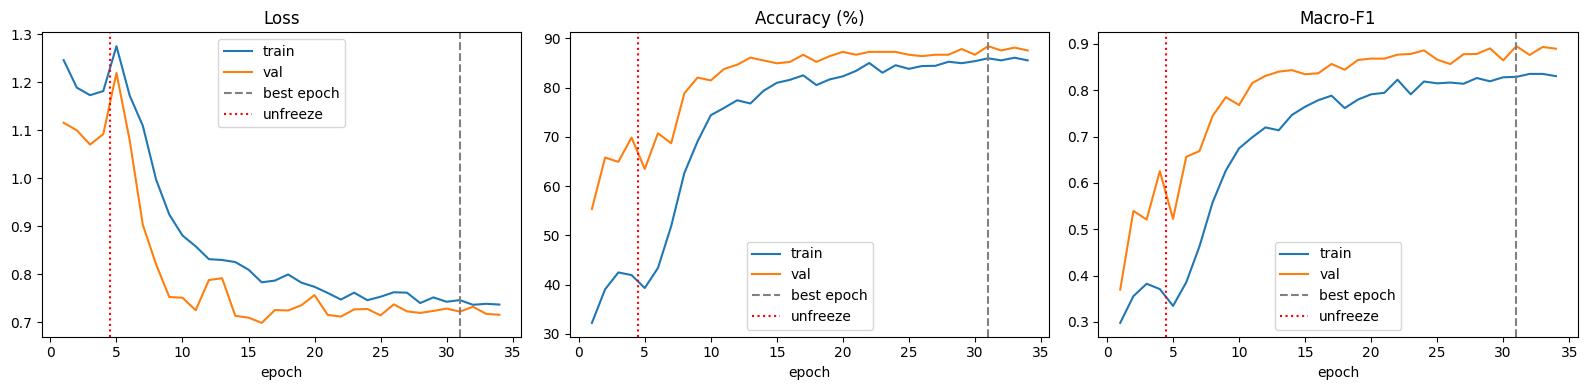

In [13]:
ep = range(1, len(history["tr_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, k, t in zip(ax, ["loss", "acc", "f1"], ["Loss", "Accuracy (%)", "Macro-F1"]):
    a.plot(ep, history["tr_" + k], label="train"); a.plot(ep, history["va_" + k], label="val")
    a.axvline(best["epoch"], color="gray", ls="--", label="best epoch"); a.axvline(P1_EPOCHS + 0.5, color="red", ls=":", label="unfreeze")
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 14. Load Best Model & Final Evaluation (with flip TTA)

In [14]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device, weights_only=True))

for tag, loader in [("Val", val_loader), ("Test", test_loader)]:
    for tta in [False, True]:
        r = evaluate(model, loader, tta=tta)
        print(f"{tag:4} | TTA={str(tta):5} | loss {r['loss']:.4f} | acc {r['acc']:.2f}% | macro-F1 {r['f1']:.4f}")

Val  | TTA=False | loss 0.7220 | acc 88.41% | macro-F1 0.8950
Val  | TTA=True  | loss 0.7144 | acc 88.12% | macro-F1 0.8813
Test | TTA=False | loss 0.7773 | acc 87.38% | macro-F1 0.8438
Test | TTA=True  | loss 0.7711 | acc 88.35% | macro-F1 0.8551


## 15. Optional: class-bias calibration tuned on **validation only**
Searches a small additive bias per class on the log-probabilities to maximize Macro-F1 on the validation set, then applies the same bias to the test set (the test set is never used for tuning). If the val gain is tiny, ignore it.

In [15]:
def tune_bias(logits, labels, grid=np.arange(-1.0, 1.01, 0.1), rounds=2):
    logp = F.log_softmax(logits, dim=1).numpy()
    b = np.zeros(NUM_CLASSES)
    best_s = f1_score(labels, logp.argmax(1), average='macro')
    for _ in range(rounds):
        for c in [0, 2]:                         # class 1 is the fixed reference
            for v in grid:
                bb = b.copy(); bb[c] = v
                s = f1_score(labels, (logp + bb).argmax(1), average='macro')
                if s > best_s + 1e-6:
                    best_s, b = s, bb
    return b, best_s

val_logits,  val_labels  = get_logits(model, val_loader,  tta=True)
test_logits, test_labels = get_logits(model, test_loader, tta=True)

bias, val_f1_tuned = tune_bias(val_logits, val_labels)
val_f1_base = f1_score(val_labels, val_logits.argmax(1).numpy(), average='macro')
print("Bias:", np.round(bias, 2))
print(f"Val  Macro-F1: {val_f1_base:.4f} -> {val_f1_tuned:.4f}")

test_logp = F.log_softmax(test_logits, dim=1).numpy()
test_f1_base  = f1_score(test_labels, test_logp.argmax(1), average='macro')
test_f1_tuned = f1_score(test_labels, (test_logp + bias).argmax(1), average='macro')
print(f"Test Macro-F1: {test_f1_base:.4f} -> {test_f1_tuned:.4f}")

# Choose which predictions to report below: calibrated only if it helped on VAL
USE_BIAS = val_f1_tuned > val_f1_base + 0.005
print("Using bias calibration:", USE_BIAS)
final_preds = (test_logp + (bias if USE_BIAS else 0)).argmax(1)

Bias: [-0.   0.   0.1]
Val  Macro-F1: 0.8813 -> 0.8893
Test Macro-F1: 0.8551 -> 0.8565
Using bias calibration: True


## 16. Additional Metrics (Balanced Accuracy / QWK / Classification Report)

In [16]:
qwk = cohen_kappa_score(test_labels, final_preds, labels=[0, 1, 2], weights="quadratic")
bal_acc = balanced_accuracy_score(test_labels, final_preds) * 100
print(f"Test accuracy:       {100*np.mean(final_preds == test_labels):.2f}%")
print(f"Balanced Accuracy:   {bal_acc:.2f}%")
print(f"Macro-F1:            {f1_score(test_labels, final_preds, average='macro'):.4f}")
print(f"Quadratic Weighted Kappa (QWK): {qwk:.4f}\n")
print("Classification Report (Test Set):")
print(classification_report(test_labels, final_preds, labels=[0, 1, 2],
                            target_names=class_names, zero_division=0, digits=3))

Test accuracy:       88.35%
Balanced Accuracy:   85.10%
Macro-F1:            0.8565
Quadratic Weighted Kappa (QWK): 0.8378

Classification Report (Test Set):
              precision    recall  f1-score   support

     Grade 2      0.926     0.919     0.923       447
     Grade 3      0.808     0.830     0.819       223
     Grade 4      0.854     0.804     0.828        51

    accuracy                          0.883       721
   macro avg      0.863     0.851     0.856       721
weighted avg      0.884     0.883     0.884       721



## 17. Confusion Matrix

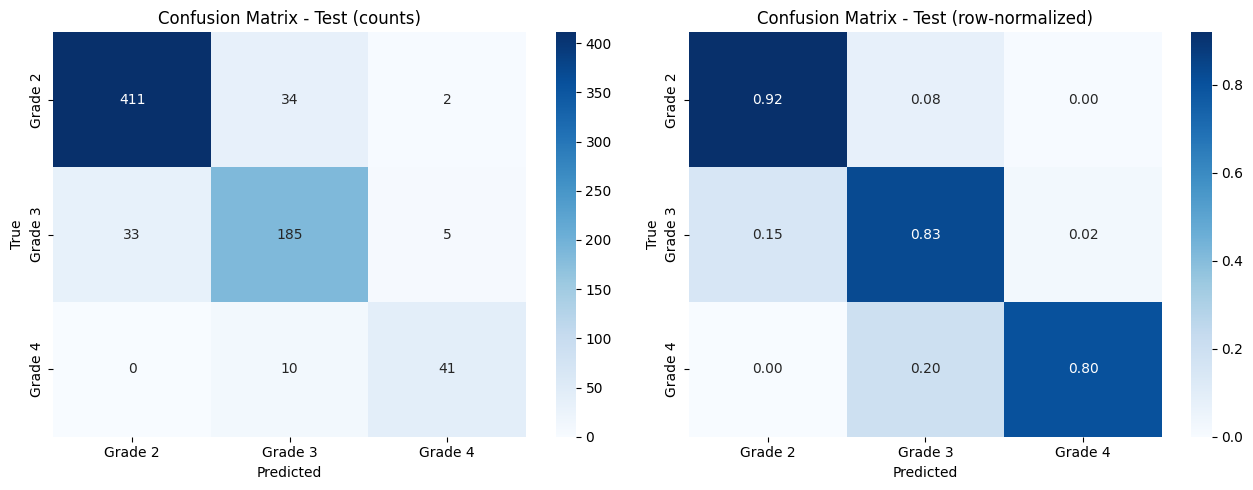

In [17]:
cm = confusion_matrix(test_labels, final_preds, labels=[0, 1, 2])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title('Confusion Matrix - Test (counts)'); ax[0].set_ylabel('True'); ax[0].set_xlabel('Predicted')
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title('Confusion Matrix - Test (row-normalized)'); ax[1].set_ylabel('True'); ax[1].set_xlabel('Predicted')
plt.tight_layout(); plt.show()